In [3]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor

In [4]:
from urllib.request import urlretrieve

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-05.parquet"

destination = data_dir / "yellow_tripdata_2026-05.parquet"

if not destination.exists():
    urlretrieve(url, destination)
    print("Téléchargement terminé")
else:
    print("Le fichier existe déjà")

Téléchargement terminé


In [5]:
data_path = Path("data/yellow_tripdata_2026-05.parquet")

if not data_path.exists():
    raise FileNotFoundError(f"Fichier introuvable : {data_path}")

data_path

PosixPath('data/yellow_tripdata_2026-05.parquet')

In [6]:
df = pd.read_parquet(data_path)
df.shape

(4090836, 20)

In [7]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
]

df[columns].head()

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance
0,2026-05-01 00:04:59,2026-05-01 00:32:48,138,37,7.51
1,2026-05-01 00:37:05,2026-05-01 00:59:47,138,237,6.14
2,2026-05-01 00:34:05,2026-05-01 00:54:02,249,232,2.40
3,2026-05-01 00:55:07,2026-05-01 01:02:43,232,114,1.20
4,2026-05-01 00:44:13,2026-05-01 00:44:13,140,237,0.86


In [8]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["duration"].describe()

count    4.090836e+06
mean     1.877588e+01
std      2.671057e+01
min      0.000000e+00
25%      8.583333e+00
50%      1.448333e+01
75%      2.326667e+01
max      9.960150e+03
Name: duration, dtype: float64

Calculer la durée

In [9]:
df = df[df["duration"].between(1, 60)].copy()

categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)
df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]

df.shape

(3883752, 22)

Filtrer et préparer les variables
PU_DO représente une combinaison entre la zone de départ et la zone d'arrivée.

In [10]:
sample_size = min(200_000, len(df))
df = df.sample(n=sample_size, random_state=42)
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

Pour limiter la mémoire utilisée, conservez un échantillon reproductible :
La valeur random_state=42 permet d'obtenir le même échantillon lors d'une nouvelle exécution.


In [11]:
split_index = int(len(df) * 0.8)

df_train = df.iloc[:split_index].copy()
df_val = df.iloc[split_index:].copy()

len(df_train), len(df_val)

(160000, 40000)

Séparer entraînement et validation

In [12]:
features = ["PU_DO", "trip_distance"]

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer()
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

y_train = df_train["duration"].to_numpy()
y_val = df_val["duration"].to_numpy()

X_train.shape, X_val.shape

((160000, 12641), (40000, 12641))

Transformer les variables
fit_transform apprend les catégories sur l'entraînement. transform applique la même transformation à la validation.

Nous utilisons DictVectorizer pour simplifier la préparation des données. Il reçoit directement une liste de dictionnaires, transforme les variables catégorielles en colonnes binaires et conserve les variables numériques. Il produit ainsi une matrice exploitable par le modèle sans créer manuellement une colonne pour chaque catégorie.

D'autres encodeurs peuvent être utilisés selon le besoin :

OneHotEncoder crée une colonne binaire pour chaque catégorie et s'intègre facilement dans un pipeline scikit-learn ;
OrdinalEncoder remplace les catégories par des nombres entiers et convient surtout lorsqu'elles possèdent un ordre réel ;
TargetEncoder utilise la relation entre une catégorie et la cible, avec des précautions pour éviter les fuites de données ;
FeatureHasher limite la taille de la représentation lorsque le nombre de catégories est très élevé.
Le choix de l'encodeur dépend du modèle, du nombre de catégories et du risque de produire une matrice trop volumineuse.



In [13]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_val)
linear_rmse = root_mean_squared_error(y_val, linear_predictions)

linear_rmse

6.652960095195363

Entraîner la régression linéaire

La régression linéaire apprend une relation linéaire entre les variables et la durée. Elle est rapide et constitue une référence simple pour évaluer les modèles suivants.
La RMSE mesure l'écart entre les durées prédites et les durées réelles. Elle est exprimée en minutes. Une valeur plus faible indique une erreur moyenne mieux maîtrisée, avec une pénalisation plus forte des grandes erreurs.



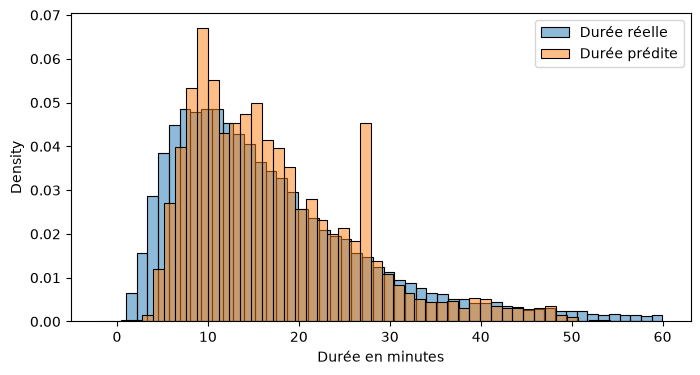

In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(y_val, label="Durée réelle", stat="density", bins=50, alpha=0.5)
sns.histplot(
    linear_predictions,
    label="Durée prédite",
    stat="density",
    bins=50,
    alpha=0.5,
)
plt.xlabel("Durée en minutes")
plt.legend()
plt.show()

Comparer les distributions
Comparez la position et l'étalement des deux distributions. Ce graphique complète la métrique sans montrer l'erreur de chaque trajet.



In [15]:
lasso_model = Lasso(alpha=0.01, max_iter=10_000)
lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse

ValueError: Only sparse matrices with 32-bit integer indices are accepted. Got int64 indices. Please do report a minimal reproducer on scikit-learn issue tracker so that support for your use-case can be studied by maintainers. See: https://scikit-learn.org/dev/developers/minimal_reproducer.html

In [16]:
import numpy as np

X_train = X_train.tocsc()
X_val = X_val.tocsc()

X_train.indices = X_train.indices.astype(np.int32)
X_train.indptr = X_train.indptr.astype(np.int32)

X_val.indices = X_val.indices.astype(np.int32)
X_val.indptr = X_val.indptr.astype(np.int32)

print("Correction effectuée")
print("X_train :", X_train.indices.dtype)
print("X_val :", X_val.indices.dtype)

Correction effectuée
X_train : int32
X_val : int32


In [17]:
lasso_model = Lasso(alpha=0.01, max_iter=10_000)
lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse

10.517043400486218

Le modèle Lasso est une régression linéaire régularisée. Le paramètre alpha pénalise les coefficients et peut ramener certains d'entre eux à zéro. Cette propriété peut réduire l'influence de variables peu utiles.

In [18]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)

xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)

xgb_rmse

6.471618951707119

XGBoost construit successivement plusieurs arbres de décision. Chaque nouvel arbre cherche à corriger une partie des erreurs commises par les arbres précédents. Le modèle peut apprendre des relations non linéaires, mais son entraînement demande davantage de ressources et de paramètres à contrôler.

Les principaux paramètres sont :

n_estimators : nombre d'arbres construits ;
max_depth : profondeur maximale de chaque arbre ;
learning_rate : contribution de chaque nouvel arbre ;
random_state : valeur utilisée pour rendre l'entraînement reproductible.

In [19]:
results = pd.DataFrame(
    {
        "model": ["LinearRegression", "Lasso", "XGBoost"],
        "rmse": [linear_rmse, lasso_rmse, xgb_rmse],
    }
).sort_values("rmse")

results

,model,rmse
2,XGBoost,6.471619
0,LinearRegression,6.652960
1,Lasso,10.517043


Comparez les trois modèles

In [20]:
models = {
    "LinearRegression": (linear_model, linear_rmse),
    "Lasso": (lasso_model, lasso_rmse),
    "XGBoost": (xgb_model, xgb_rmse),
}

selected_name = min(models, key=lambda name: models[name][1])
selected_model, selected_rmse = models[selected_name]

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "duration_model.bin"

with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

selected_name, selected_rmse, model_path

('XGBoost', 6.471618951707119, PosixPath('models/duration_model.bin'))

Le module Python pickle permet de sérialiser un objet, c'est-à-dire de convertir son état en données enregistrables dans un fichier. Le fichier peut ensuite être chargé dans une autre exécution Python sans entraîner de nouveau le modèle.

Dans ce TP, nous enregistrons ensemble :

dv, le DictVectorizer qui connaît les colonnes créées pendant l'entraînement ;
selected_model, le modèle qui utilise ces colonnes pour effectuer une prédiction.
Conserver uniquement le modèle ne suffit pas. Les nouvelles données doivent subir exactement la même transformation que les données d'entraînement.

Un fichier pickle dépend des classes et des versions de bibliothèques utilisées pour le créer. Il ne doit être chargé que depuis une source de confiance, car son chargement peut exécuter du code Python.



In [21]:
with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)

example = [{"PU_DO": "161_236", "trip_distance": 3.2}]

example_matrix = loaded_dv.transform(example)

# Compatibilité avec Lasso dans ton environnement
example_matrix.indices = example_matrix.indices.astype(np.int32)
example_matrix.indptr = example_matrix.indptr.astype(np.int32)

prediction = loaded_model.predict(example_matrix)[0]

prediction

np.float32(21.65231)

Rechargez le fichier dans une nouvelle cellule :



In [22]:
lasso_model_001 = Lasso(
    alpha=0.001,
    max_iter=10_000
)

lasso_model_001.fit(X_train, y_train)

lasso_predictions_001 = lasso_model_001.predict(X_val)

lasso_rmse_001 = root_mean_squared_error(
    y_val, lasso_predictions_001
)

lasso_rmse_001

7.87729437908463

Cellule 1 : Lasso avec alpha=0.001

In [23]:
lasso_model_01 = Lasso(
    alpha=0.1,
    max_iter=10_000
)

lasso_model_01.fit(X_train, y_train)

lasso_predictions_01 = lasso_model_01.predict(X_val)

lasso_rmse_01 = root_mean_squared_error(
    y_val, lasso_predictions_01
)

lasso_rmse_01

10.97771869202461

Cellule 2 : Lasso avec alpha=0.1

In [24]:
xgb_model_depth8 = XGBRegressor(
    n_estimators=100,
    max_depth=8,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

xgb_model_depth8.fit(X_train, y_train)

xgb_predictions_depth8 = xgb_model_depth8.predict(X_val)

xgb_rmse_depth8 = root_mean_squared_error(
    y_val, xgb_predictions_depth8
)

xgb_rmse_depth8

6.437837552097515

Modifiez un paramètre de XGBoost et relancez son entraînement.

In [25]:
experiments = pd.DataFrame({
    "model": [
        "LinearRegression",
        "Lasso",
        "Lasso",
        "Lasso",
        "XGBoost",
        "XGBoost"
    ],
    "hyperparametres": [
        "Default",
        "alpha=0.01",
        "alpha=0.001",
        "alpha=0.1",
        "max_depth=6",
        "max_depth=8"
    ],
    "rmse": [
        linear_rmse,
        lasso_rmse,
        lasso_rmse_001,
        lasso_rmse_01,
        xgb_rmse,
        xgb_rmse_depth8
    ]
})

experiments = experiments.sort_values(
    "rmse"
).reset_index(drop=True)

experiments

,model,hyperparametres,rmse
0,XGBoost,max_depth=8,6.437838
1,XGBoost,max_depth=6,6.471619
2,LinearRegression,Default,6.652960
3,Lasso,alpha=0.001,7.877294
4,Lasso,alpha=0.01,10.517043
5,Lasso,alpha=0.1,10.977719


 Notez la RMSE de validation de chaque essai

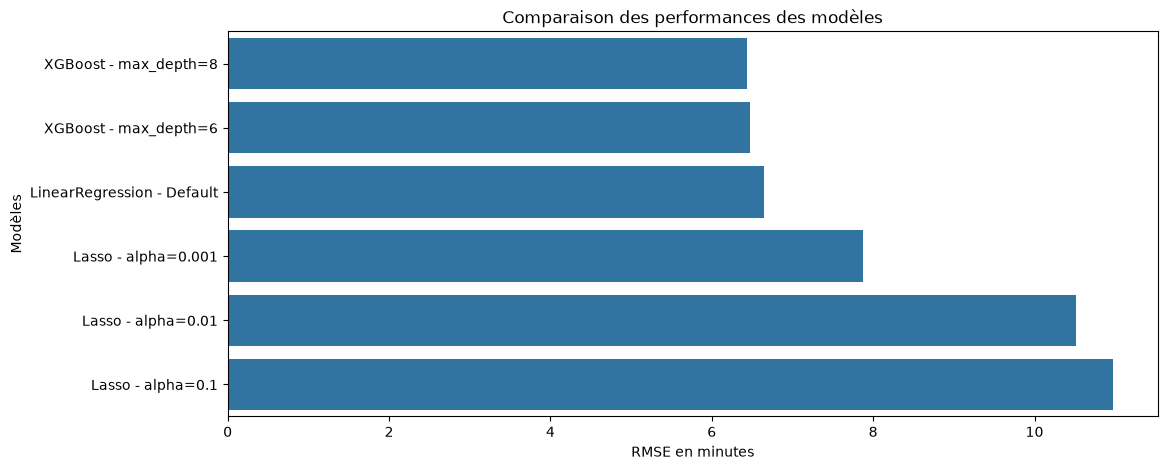

In [26]:
experiments["configuration"] = (
    experiments["model"] + " - " +
    experiments["hyperparametres"]
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=experiments,
    x="rmse",
    y="configuration"
)

plt.title("Comparaison des performances des modèles")
plt.xlabel("RMSE en minutes")
plt.ylabel("Modèles")
plt.show()

Visualisation graphique 

In [27]:
all_models = {
    "LinearRegression": (
        linear_model, linear_rmse
    ),
    "Lasso alpha=0.01": (
        lasso_model, lasso_rmse
    ),
    "Lasso alpha=0.001": (
        lasso_model_001, lasso_rmse_001
    ),
    "Lasso alpha=0.1": (
        lasso_model_01, lasso_rmse_01
    ),
    "XGBoost max_depth=6": (
        xgb_model, xgb_rmse
    ),
    "XGBoost max_depth=8": (
        xgb_model_depth8, xgb_rmse_depth8
    )
}

selected_name = min(
    all_models,
    key=lambda name: all_models[name][1]
)

selected_model, selected_rmse = all_models[selected_name]

print("Modèle retenu :", selected_name)
print(f"RMSE de validation : {selected_rmse:.4f} minutes")

Modèle retenu : XGBoost max_depth=8
RMSE de validation : 6.4378 minutes


Identifiez le modèle retenu et justifiez votre choix

In [28]:
print(
    f"Le modèle retenu est {selected_name}, "
    f"avec une RMSE de validation de "
    f"{selected_rmse:.4f} minutes. "
    "Ce modèle a été sélectionné car il présente "
    "la RMSE la plus faible parmi les six configurations "
    "testées sur le même jeu de validation. "
    "Il offre donc les meilleures performances "
    "de prédiction selon la métrique retenue."
)

Le modèle retenu est XGBoost max_depth=8, avec une RMSE de validation de 6.4378 minutes. Ce modèle a été sélectionné car il présente la RMSE la plus faible parmi les six configurations testées sur le même jeu de validation. Il offre donc les meilleures performances de prédiction selon la métrique retenue.


In [29]:
with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

print("Meilleur modèle sauvegardé :", model_path)

Meilleur modèle sauvegardé : models/duration_model.bin


Informations à conserver pour reproduire chaque essai

Pour garantir la reproductibilité des expérimentations, nous devons conserver les informations suivantes :

Catégorie	Information	Valeur utilisée dans le TP
Dataset	Fichier source	yellow_tripdata_2026-05.parquet
Échantillonnage	Taille maximale	200 000 observations
Filtrage	Durée des trajets	Entre 1 et 60 minutes
Variables explicatives	Features	PU_DO, trip_distance
Variable cible	Target	duration
Encodage	Encodeur	DictVectorizer
Entraînement	Proportion des données	80 %
Validation	Proportion des données	20 %
Séparation	Méthode	Chronologique
Graine aléatoire	random_state	42
Algorithmes	Modèles utilisés	LinearRegression, Lasso, XGBoost
Hyperparamètres	Configuration des modèles	alpha, max_iter, max_depth, learning_rate, etc.
Évaluation	Métrique	RMSE
Résultats	Performance de chaque essai	RMSE de validation obtenue
Environnement	Versions des bibliothèques	Python, Pandas, NumPy, SciPy, Scikit-learn, XGBoost
Versionnement	Version du code source	Commit Git
Artefacts	Objets sauvegardés	Modèle entraîné et DictVectorizer
Traçabilité	Date et durée d’entraînement	Informations propres à chaque essai



Ces informations permettent de reproduire les expérimentations, de comparer les performances des modèles et d’assurer leur traçabilité. L’utilisation de MLflow permettra par la suite d’automatiser leur enregistrement.

In [30]:
print("Dataset :", data_path)
print("Nombre total de trajets :", len(df))
print("Données d'entraînement :", len(df_train))
print("Données de validation :", len(df_val))
print("Variables explicatives :", features)
print("Variable cible : duration")
print("Random state : 42")
print("Encodeur :", type(dv).__name__)
print("Filtrage : entre 1 et 60 minutes")

Dataset : data/yellow_tripdata_2026-05.parquet
Nombre total de trajets : 200000
Données d'entraînement : 160000
Données de validation : 40000
Variables explicatives : ['PU_DO', 'trip_distance']
Variable cible : duration
Random state : 42
Encodeur : DictVectorizer
Filtrage : entre 1 et 60 minutes


 lister les informations sur les données

In [31]:
for name, (model, rmse) in all_models.items():

    print("=" * 60)
    print("Nom du modèle :", name)
    print("Algorithme :", type(model).__name__)
    print("Hyperparamètres :", model.get_params())
    print("RMSE :", rmse)

Nom du modèle : LinearRegression
Algorithme : LinearRegression
Hyperparamètres : {'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}
RMSE : 6.652960095195363
Nom du modèle : Lasso alpha=0.01
Algorithme : Lasso
Hyperparamètres : {'alpha': 0.01, 'copy_X': True, 'fit_intercept': True, 'max_iter': 10000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
RMSE : 10.517043400486218
Nom du modèle : Lasso alpha=0.001
Algorithme : Lasso
Hyperparamètres : {'alpha': 0.001, 'copy_X': True, 'fit_intercept': True, 'max_iter': 10000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
RMSE : 7.87729437908463
Nom du modèle : Lasso alpha=0.1
Algorithme : Lasso
Hyperparamètres : {'alpha': 0.1, 'copy_X': True, 'fit_intercept': True, 'max_iter': 10000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cycli

lister les hyperparamètres et les résultats de chaque essai

In [32]:
import sys
import platform
import numpy as np
import sklearn
import xgboost
import scipy

print("Python :", sys.version)
print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)
print("XGBoost :", xgboost.__version__)
print("SciPy :", scipy.__version__)
print("Système :", platform.platform())
print("Architecture :", platform.machine())

Python : 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:38:15) [Clang 20.1.8 ]
Pandas : 3.1.1
NumPy : 2.5.5
Scikit-learn : 1.9.1
XGBoost : 3.4.2
SciPy : 1.18.1
Système : macOS-27.0.1-arm64-arm-64bit
Architecture : arm64


 lister les versions de l’environnement

In [33]:
import json

experiment_records = []

for name, (model, rmse) in all_models.items():

    record = {
        "experiment": name,
        "algorithm": type(model).__name__,
        "parameters": model.get_params(),
        "rmse": float(rmse),
        "dataset": str(data_path),
        "training_size": len(df_train),
        "validation_size": len(df_val),
        "features": features,
        "target": "duration",
        "random_state": 42,
        "encoder": "DictVectorizer",
        "python_version": platform.python_version(),
        "sklearn_version": sklearn.__version__,
        "xgboost_version": xgboost.__version__
    }

    experiment_records.append(record)

with open("experiments.json", "w") as file:
    json.dump(experiment_records, file, indent=4, default=str)

print("Expérimentations enregistrées avec succès.")

Expérimentations enregistrées avec succès.


Enregistrer les informations dans un fichier